<a href="https://colab.research.google.com/github/Udhay345/UWrites-AI-Powered-Personalized-Handwriting-Generation/blob/main/Uwrites.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q opencv-python-headless pillow numpy torch torchvision

import os, cv2, numpy as np, torch, csv, zipfile
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image

DATA_ROOT = '/content/handwriting-dataset'
os.makedirs(DATA_ROOT, exist_ok=True)

In [ ]:
from google.colab import files
uploaded = files.upload()  # click "Choose Files" → select raw_scans.zip

zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall(DATA_ROOT)

print("Extracted to:", DATA_ROOT)
!find {DATA_ROOT}/raw_scans -type d

Saving dataset.zip to dataset.zip
Extracted to: /content/handwriting-dataset
find: ‘/content/handwriting-dataset/raw_scans’: No such file or directory


In [ ]:
def remove_ruled_lines(img_bin):
    inv = cv2.bitwise_not(img_bin)
    horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (img_bin.shape[1] // 3, 1))
    detected_lines = cv2.morphologyEx(inv, cv2.MORPH_OPEN, horiz_kernel, iterations=1)
    cnts, _ = cv2.findContours(detected_lines, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cleaned = img_bin.copy()
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(cleaned, (x, y - 1), (x + w, y + h + 1), 255, -1)
    return cleaned

def deskew(img):
    gray = cv2.bitwise_not(img)
    thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
    coords = np.column_stack(np.where(thresh > 0))
    if len(coords) == 0:
        return img
    angle = cv2.minAreaRect(coords)[-1]
    angle = -(90 + angle) if angle < -45 else -angle
    (h, w) = img.shape[:2]
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def binarize(img):
    return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 25, 12)

def segment_lines(img_bin, min_gap=4):
    proj = np.sum(img_bin == 0, axis=1)
    lines, in_line, start, gap = [], False, 0, 0
    for i, v in enumerate(proj):
        if v > 0:
            if not in_line: start, in_line = i, True
            gap = 0
        else:
            gap += 1
            if in_line and gap > min_gap:
                lines.append((start, i - gap)); in_line = False
    if in_line: lines.append((start, len(proj)))
    return lines

def segment_words(line_img_bin, gap_threshold=15):
    proj = np.sum(line_img_bin == 0, axis=0)
    words, in_word, start, gap = [], False, 0, 0
    for i, v in enumerate(proj):
        if v > 0:
            if not in_word: start, in_word = i, True
            gap = 0
        else:
            gap += 1
            if in_word and gap > gap_threshold:
                words.append((start, i - gap)); in_word = False
    if in_word: words.append((start, len(proj)))
    return words

def process_page(path, out_dir, page_id, is_ruled):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f'WARNING: could not read {path}'); return []
    img = deskew(img)
    img_bin = binarize(img)
    if is_ruled:
        img_bin = remove_ruled_lines(img_bin)
    os.makedirs(out_dir, exist_ok=True)
    saved = []
    for li, (y0, y1) in enumerate(segment_lines(img_bin)):
        if y1 - y0 < 8:
            continue
        line_bin = img_bin[y0:y1, :]
        line_orig = img[y0:y1, :]
        for wi, (x0, x1) in enumerate(segment_words(line_bin)):
            if x1 - x0 < 5:
                continue
            crop = line_orig[:, x0:x1]
            fname = f'{page_id}_line{li:02d}_word{wi:02d}.png'
            cv2.imwrite(os.path.join(out_dir, fname), crop)
            saved.append(fname)
    return saved

In [ ]:
FOLDER_MAP = {
    'sentences': 'sentences',
    'capital letters': 'capital_letters',
    'small letters': 'small_letters',
    'collection': 'mixed_case',
    'numbers': 'numbers',
    'characters': 'special_characters',
}
RULING = ['ruled', 'unruled']

seg_root = f'{DATA_ROOT}/segmented'
os.makedirs(f'{DATA_ROOT}/labels', exist_ok=True)

# Build a lookup of every directory under DATA_ROOT, keyed by lowercase name
dir_lookup = {}
for root, dirs, _ in os.walk(DATA_ROOT):
    for d in dirs:
        dir_lookup.setdefault(d.lower().strip(), []).append(os.path.join(root, d))

def find_dir(name):
    matches = dir_lookup.get(name.lower().strip())
    return matches[0] if matches else None

all_rows = []

for real_name, category in FOLDER_MAP.items():
    category_dir = find_dir(real_name)
    if not category_dir:
        print(f'Could not find folder for: {real_name}')
        continue

    for ruling in RULING:
        ruling_dir = None
        for d in os.listdir(category_dir):
            if d.lower().strip() == ruling and os.path.isdir(os.path.join(category_dir, d)):
                ruling_dir = os.path.join(category_dir, d)
                break
        if not ruling_dir:
            print(f'Skipping missing: {real_name}/{ruling}')
            continue

        out_dir = os.path.join(seg_root, category, ruling)
        is_ruled = (ruling == 'ruled')

        for page_file in sorted(os.listdir(ruling_dir)):
            if not page_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue
            page_id = os.path.splitext(page_file)[0]
            saved = process_page(os.path.join(ruling_dir, page_file), out_dir, page_id, is_ruled)
            for fname in saved:
                all_rows.append({
                    'filename': fname,
                    'category': category,
                    'ruling': ruling,
                    'relpath': f'{category}/{ruling}/{fname}',
                    'transcription': ''
                })

label_path = f'{DATA_ROOT}/labels/all_words_template.csv'
with open(label_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['filename', 'category', 'ruling', 'relpath', 'transcription'])
    writer.writeheader()
    writer.writerows(all_rows)

print(f'Segmented {len(all_rows)} word images across {len(FOLDER_MAP)} categories.')

Segmented 1519 word images across 6 categories.


In [ ]:
from google.colab import files
files.download(label_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!zip -r -q segmented_words.zip {seg_root}
files.download('segmented_words.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd
import csv

# Step 1: Upload your labeled file (xlsx or csv, either works now)
uploaded = files.upload()
uploaded_name = list(uploaded.keys())[0]
print(f'Uploaded: {uploaded_name}')

# Step 2: If it's an Excel file, convert it to CSV
if uploaded_name.lower().endswith(('.xlsx', '.xls')):
    df = pd.read_excel(uploaded_name)
    labeled_csv = 'all_words_labeled.csv'
    df.to_csv(labeled_csv, index=False)
    print(f'Converted Excel → CSV: {labeled_csv}')
else:
    labeled_csv = uploaded_name

# Step 3: Sanity check — confirm rows and how many are actually labeled
total = 0
empty = 0
with open(labeled_csv) as f:
    reader = csv.DictReader(f)
    for row in reader:
        total += 1
        if not row['transcription'].strip():
            empty += 1

print(f'Total rows: {total}')
print(f'Empty transcriptions: {empty}')
print(f'Usable for training: {total - empty}')

Saving labeled_csv.xlsx to labeled_csv.xlsx
Uploaded: labeled_csv.xlsx
Converted Excel → CSV: all_words_labeled.csv
Total rows: 1519
Empty transcriptions: 207
Usable for training: 1312


In [ ]:
CHARS = " abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.,!?'\"-"
CHAR2IDX = {c: i for i, c in enumerate(CHARS)}
IMG_H, IMG_W = 64, 256

class HandwritingDataset(Dataset):
    def __init__(self, csv_path, img_root):
        self.samples = []
        with open(csv_path) as f:
            reader = csv.DictReader(f)
            for row in reader:
                if row['transcription'].strip():
                    self.samples.append((row['relpath'], row['transcription']))
        self.img_root = img_root

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        relpath, text = self.samples[idx]
        img = Image.open(os.path.join(self.img_root, relpath)).convert('L')
        img = img.resize((IMG_W, IMG_H))
        img = np.array(img, dtype=np.float32) / 127.5 - 1.0
        img = torch.tensor(img).unsqueeze(0)
        text_ids = torch.tensor([CHAR2IDX.get(c, 0) for c in text[:20]])
        return img, text_ids

dataset = HandwritingDataset(labeled_csv, seg_root)
print(f'Usable training samples: {len(dataset)}')

Usable training samples: 1312


In [ ]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim)
        self.gru = nn.GRU(embed_dim, embed_dim, batch_first=True, bidirectional=True)

    def forward(self, text_ids):
        e = self.embed(text_ids)
        _, h = self.gru(e)
        return torch.cat([h[0], h[1]], dim=1)

class Generator(nn.Module):
    def __init__(self, z_dim=128, text_dim=128):
        super().__init__()
        self.fc = nn.Linear(z_dim + text_dim, 512 * 4 * 16)
        self.net = nn.Sequential(
            nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh(),
        )

    def forward(self, z, text_feat):
        x = torch.cat([z, text_feat], dim=1)
        x = self.fc(x).view(-1, 512, 4, 16)
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Conv2d(256, 512, 4, 2, 1), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, True),
            nn.Conv2d(512, 1, 4, 1, 0),
        )

    def forward(self, img):
        return self.net(img).view(-1)

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

loader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda b: (
    torch.stack([x[0] for x in b]),
    nn.utils.rnn.pad_sequence([x[1] for x in b], batch_first=True),
))

text_enc = TextEncoder(len(CHARS)).to(device)
G = Generator().to(device)
D = Discriminator().to(device)

opt_G = torch.optim.Adam(list(G.parameters()) + list(text_enc.parameters()), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 200
CKPT_DIR = f'{DATA_ROOT}/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

Using device: cuda


In [ ]:
import time
start = time.time()

for epoch in range(EPOCHS):
    for real_img, text_ids in loader:
        real_img, text_ids = real_img.to(device), text_ids.to(device)
        bsz = real_img.size(0)
        text_feat = text_enc(text_ids)

        z = torch.randn(bsz, 128, device=device)
        fake_img = G(z, text_feat)
        d_real = D(real_img)
        d_fake = D(fake_img.detach())
        loss_D = criterion(d_real, torch.ones_like(d_real)) + criterion(d_fake, torch.zeros_like(d_fake))
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        d_fake2 = D(fake_img)
        loss_G = criterion(d_fake2, torch.ones_like(d_fake2))
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

    if epoch % 5 == 0:
        elapsed = time.time() - start
        print(f'Epoch {epoch}: D={loss_D.item():.4f} G={loss_G.item():.4f} | {elapsed:.0f}s elapsed')

    if epoch % 20 == 0:
        ckpt_path = f'{CKPT_DIR}/ckpt_epoch{epoch}.pt'
        torch.save({'G': G.state_dict(), 'text_enc': text_enc.state_dict()}, ckpt_path)

print(f'Total training time: {(time.time()-start)/60:.1f} minutes')

Epoch 0: D=0.0039 G=7.4809 | 7s elapsed
Epoch 5: D=0.1423 G=3.4806 | 33s elapsed
Epoch 10: D=0.0176 G=4.8065 | 61s elapsed
Epoch 15: D=0.0023 G=6.9788 | 90s elapsed
Epoch 20: D=0.0009 G=7.5881 | 119s elapsed
Epoch 25: D=0.7015 G=9.4554 | 147s elapsed
Epoch 30: D=0.0210 G=7.0232 | 175s elapsed
Epoch 35: D=0.0330 G=4.7570 | 204s elapsed
Epoch 40: D=0.9010 G=3.5407 | 232s elapsed
Epoch 45: D=0.2483 G=4.7280 | 261s elapsed
Epoch 50: D=0.3092 G=2.8917 | 289s elapsed
Epoch 55: D=0.1677 G=4.8117 | 318s elapsed
Epoch 60: D=0.3076 G=4.2165 | 346s elapsed
Epoch 65: D=0.0983 G=4.9566 | 374s elapsed
Epoch 70: D=0.0738 G=4.4420 | 403s elapsed
Epoch 75: D=0.0653 G=4.8733 | 431s elapsed
Epoch 80: D=0.0537 G=5.7692 | 459s elapsed
Epoch 85: D=0.1626 G=5.3863 | 488s elapsed
Epoch 90: D=0.0227 G=9.4597 | 516s elapsed
Epoch 95: D=0.2298 G=3.1720 | 544s elapsed
Epoch 100: D=0.0903 G=4.9848 | 572s elapsed
Epoch 105: D=0.0784 G=4.5564 | 601s elapsed
Epoch 110: D=0.0188 G=10.0036 | 629s elapsed
Epoch 115: D=0

In [ ]:
import glob, os

ckpts = glob.glob(f'{CKPT_DIR}/*.pt')
latest = max(ckpts, key=os.path.getmtime)
print(f'Downloading: {latest}')
files.download(latest)

Downloading: /content/handwriting-dataset/checkpoints/ckpt_epoch180.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!zip -r -q all_checkpoints.zip {CKPT_DIR}
files.download('all_checkpoints.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Available checkpoints:
ckpt_epoch0.pt	  ckpt_epoch140.pt  ckpt_epoch20.pt  ckpt_epoch80.pt
ckpt_epoch100.pt  ckpt_epoch160.pt  ckpt_epoch40.pt
ckpt_epoch120.pt  ckpt_epoch180.pt  ckpt_epoch60.pt

Using checkpoint: /content/handwriting-dataset/checkpoints/ckpt_epoch180.pt

"u":


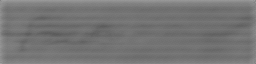

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display

def generate_word(text, ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    G.load_state_dict(ckpt['G'])
    text_enc.load_state_dict(ckpt['text_enc'])
    G.eval()
    text_enc.eval()

    text_ids = torch.tensor([[CHAR2IDX.get(c, 0) for c in text[:20]]]).to(device)
    z = torch.randn(1, 128, device=device)
    with torch.no_grad():
        feat = text_enc(text_ids)
        img = G(z, feat)[0, 0].cpu().numpy()

    img = ((img + 1) * 127.5).clip(0, 255).astype(np.uint8)
    return Image.fromarray(img)

# Check available checkpoints
print("Available checkpoints:")
!ls {CKPT_DIR}

# Pick the latest one automatically
import glob, os
ckpts = glob.glob(f'{CKPT_DIR}/*.pt')
latest_ckpt = max(ckpts, key=os.path.getmtime)
print(f'\nUsing checkpoint: {latest_ckpt}\n')

# Generate and display a few test words
test_words = ['u']
for word in test_words:
    img = generate_word(word, latest_ckpt)
    img.save(f'/content/test_{word}.png')
    print(f'"{word}":')
    display(img)

# Zip and download all test outputs
!zip -q test_outputs.zip /content/test_*.png
from google.colab import files
files.download('test_outputs.zip')